C:\Users\frdch\AppData\Local\Temp\ipykernel_16512\2539194439.py:44: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  im_close = morphology.binary_closing(im_dilate, morphology.square(size))


Top 4 TL scores: [11]
Top 4 TR scores: [11]
Top 4 BL scores: [182]
Top 4 BR scores: [182]
Résultat final sans doublons: [ 11   0 177 182]


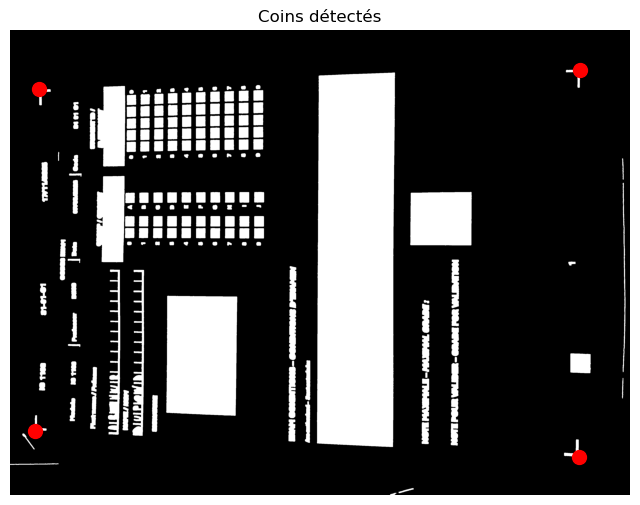

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy.optimize as sp
import skimage.io as ski 
import os
from skimage import color
from skimage import filters
from skimage import feature
from skimage.transform import hough_line, hough_line_peaks
from skimage import feature, morphology
from scipy.ndimage import binary_fill_holes
import skimage
from scipy import ndimage




# import skimage.io as ski
# im = ski.imread("FORM1/EXAM_FORM1_62445.jpg")
# im = ski.imread("FORM1\EXAM_FORM1_61856.jpg")
# im = ski.imread("FORM1\EXAM_FORM1_62401.jpg") # image de reférence
im = ski.imread("FORM1\EXAM_FORM1_54331.jpg") # 2 image 
# im = ski.imread("FORM1\EXAM_FORM1_61856.jpg") # image de malfaite 2 coins
# im = ski.imread("FORM1\EXAM_FORM1_62034.jpeg") # image de malfaite s
# im = ski.imread("FORM1\EXAM_FORM1_62445.jpg") # image de malfaite s


# im = ski.imread("EXAM_FORM1_54331.jpg")
# im = ski.imread("EXAM_FORM1_58220.jpg")

im_rgb = im[:, :, :3]  # on garde uniquement R, G, B
im2 = color.rgb2gray(im_rgb)

# dir(skimage.filters)
im3 = filters.sobel(im2)


size = 5
seuil = filters.threshold_otsu(im3)
im4 = im3>seuil*0.7
im4 = morphology.remove_small_objects(im4, min_size=100)
im_dilate = ndimage.binary_dilation(im4, structure=np.ones((size, size)))
im_close = morphology.binary_closing(im_dilate, morphology.square(size))
im4 = binary_fill_holes(im_close)
imlabel, nbCC   = skimage.measure.label(im4, connectivity=2, return_num= True)
regionprops= skimage.measure.regionprops(imlabel)

bestCoinTL = []

bestCoinTR = []

bestCoinBL = []

bestCoinBR = []



# listg=[]

for k in range(len(regionprops)):

    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    pattern = imlabel[min_row:max_row, min_col:max_col] > 0
    
    dimL, diml = pattern.shape
    matCoin = np.ones((dimL, diml))
    edge = int(min(dimL, diml) * 0.20)
    matCoin[edge:, edge:] = 0


    scoreTL = np.corrcoef(matCoin.flatten(), pattern.flatten())[0, 1]
    scoreTR = np.corrcoef(np.rot90(matCoin, 3).flatten(), pattern.flatten())[0, 1]
    scoreBL = np.corrcoef(np.rot90(matCoin, 1).flatten(), pattern.flatten())[0, 1]
    scoreBR = np.corrcoef(np.rot90(matCoin, 2).flatten(), pattern.flatten())[0, 1]

    bestCoinTL.append(scoreTL)
    bestCoinTR.append(scoreTR)
    bestCoinBL.append(scoreBL)
    bestCoinBR.append(scoreBR)
    # listg.append(max(scoreTL, scoreTR, scoreBL, scoreBR))

npbestCoinTL = np.array(bestCoinTL)
npbestCoinTR = np.array(bestCoinTR)
npbestCoinBL = np.array(bestCoinBL)
npbestCoinBR = np.array(bestCoinBR)
# nplistg = np.array(listg)

sortbestCoinTL = np.argsort(npbestCoinTL)
sortbestCoinTR = np.argsort(npbestCoinTR)
sortbestCoinBL = np.argsort(npbestCoinBL)
sortbestCoinBR = np.argsort(npbestCoinBR)
# sortlistg = np.argsort(nplistg)

print("Top 4 TL scores:", sortbestCoinTL[-1:])
print("Top 4 TR scores:", sortbestCoinTR[-1:])
print("Top 4 BL scores:", sortbestCoinBL[-1:])
print("Top 4 BR scores:", sortbestCoinBR[-1:])

tabCoin = np.array([[npbestCoinTL], [npbestCoinTR], [npbestCoinBL], [npbestCoinBR]])


listTop4 = np.array([
    sortbestCoinTL[-1],
    sortbestCoinTR[-1],
    sortbestCoinBL[-1],
    sortbestCoinBR[-1]
])



# positions dans les listes triées
pos = [ -1, -1, -1, -1 ]  # TL, TR, BL, BR

while len(np.unique(listTop4)) != 4:

    values, counts = np.unique(listTop4, return_counts=True)
    doublons_values = values[counts > 1]

    for val in doublons_values:

        doublons_indices = np.where(listTop4 == val)[0]

        corMax = []

        # récupérer les scores
        for i in doublons_indices:
            if i == 0:
                corMax.append(npbestCoinTL[listTop4[i]])
            elif i == 1:
                corMax.append(npbestCoinTR[listTop4[i]])
            elif i == 2:
                corMax.append(npbestCoinBL[listTop4[i]])
            elif i == 3:
                corMax.append(npbestCoinBR[listTop4[i]])

        corMax = np.array(corMax)

        # garder le meilleur → remplacer les autres
        best = doublons_indices[np.argmax(corMax)]

        for i in doublons_indices:
            if i != best:
                pos[i] -= 1  # on descend au candidat suivant

                if i == 0:
                    listTop4[i] = sortbestCoinTL[pos[i]]
                elif i == 1:
                    listTop4[i] = sortbestCoinTR[pos[i]]
                elif i == 2:
                    listTop4[i] = sortbestCoinBL[pos[i]]
                elif i == 3:
                    listTop4[i] = sortbestCoinBR[pos[i]]
                

print("Résultat final sans doublons:", listTop4)


threshold = 0.22

points = []  # liste des coordonnées

for i in range(4):
    idx = listTop4[i]

    # récupérer score
    if i == 0:
        score = npbestCoinTL[idx]
    elif i == 1:
        score = npbestCoinTR[idx]
    elif i == 2:
        score = npbestCoinBL[idx]
    elif i == 3:
        score = npbestCoinBR[idx]

    # garder seulement si valide
    if score >= threshold:

        min_row, min_col, max_row, max_col = regionprops[idx].bbox

        if i == 0:  # TL
            pt = (min_col, min_row)
        elif i == 1:  # TR
            pt = (max_col, min_row)
        elif i == 2:  # BL
            pt = (min_col, max_row)
        elif i == 3:  # BR
            pt = (max_col, max_row)

        points.append(pt)

plt.figure(figsize=(8,8))
plt.imshow(im4, cmap='gray')

for pt in points:
    x, y = pt
    plt.plot(x, y, 'ro', markersize=10)

plt.title("Coins détectés")
plt.axis('off')
plt.show()


    
        



In [5]:

print("\nCorrélations finales :")

for i in range(4):
    idx = listTop4[i]

    if i == 0:
        score = npbestCoinTL[idx]
        name = "TL"
    elif i == 1:
        score = npbestCoinTR[idx]
        name = "TR"
    elif i == 2:
        score = npbestCoinBL[idx]
        name = "BL"
    elif i == 3:
        score = npbestCoinBR[idx]
        name = "BR"

    print(f"{name} → indice = {idx}, corrélation = {score:.3f}")



Corrélations finales :
TL → indice = 23, corrélation = 0.846
TR → indice = 13, corrélation = 0.321
BL → indice = 191, corrélation = 0.317
BR → indice = 198, corrélation = 0.791
